In [1]:
import torch

if not torch.cuda.is_available():
    print("cuda를 사용할 수 없습니다.")
else:
    print("cuda를 사용할 수 있습니다.")

cuda를 사용할 수 있습니다.


In [2]:
from google.colab import drive
drive.mount('/content/drive')

# Classification
!unzip -q "/content/drive/MyDrive/멋사_CV캠프/project1_smartfarm/data/strawberry_data_classification.zip" -d /content/strawberry_classification
print("✅ Classification 완료!")

# Detection
!unzip -q "/content/drive/MyDrive/멋사_CV캠프/project1_smartfarm/data/strawberry_data_detection.zip" -d /content/strawberry_detection
print("✅ Detection 완료!")

# 확인
!ls /content/strawberry_classification
!ls /content/strawberry_detection



Mounted at /content/drive
✅ Classification 완료!
✅ Detection 완료!
burn  normal  rot  wilt  yellowing
images	labels


In [3]:
print("📁 Classification 구조:")
!ls -R /content/strawberry_classification | head -30

print("\n📁 Detection 구조:")
!ls -R /content/strawberry_detection | head -30

📁 Classification 구조:
/content/strawberry_classification:
burn
normal
rot
wilt
yellowing

/content/strawberry_classification/burn:
00001.jpg
00002.jpg
00003.jpg
00004.jpg
00005.jpg
00006.jpg
00007.jpg
00008.jpg
00009.jpg
00010.jpg
00011.jpg
00012.jpg
00013.jpg
00014.jpg
00015.jpg
00016.jpg
00017.jpg
00018.jpg
00019.jpg
00020.jpg
00021.jpg
00022.jpg

📁 Detection 구조:
/content/strawberry_detection:
images
labels

/content/strawberry_detection/images:
test
train
val

/content/strawberry_detection/images/test:
딸기_설향_황화_36_040_221009151154.jpg
딸기_설향_황화_36_040_221011151154.jpg
딸기_설향_황화_36_040_221012141154.jpg
딸기_설향_황화_36_040_221013161154.jpg
딸기_설향_황화_36_040_221014131154.jpg
딸기_설향_황화_36_040_221014141154.jpg
딸기_설향_황화_36_040_221015111154.jpg
딸기_설향_황화_36_040_221015131154.jpg
딸기_설향_황화_36_040_221015161154.jpg
딸기_설향_황화_36_040_221017161154.jpg
딸기_설향_황화_36_040_221018081154.jpg
딸기_설향_황화_36_040_221018101154.jpg
딸기_설향_황화_36_040_221018151154.jpg
딸기_설향_황화_36_040_221019161154.jpg
딸기_설향_황화_36_040_221020081154

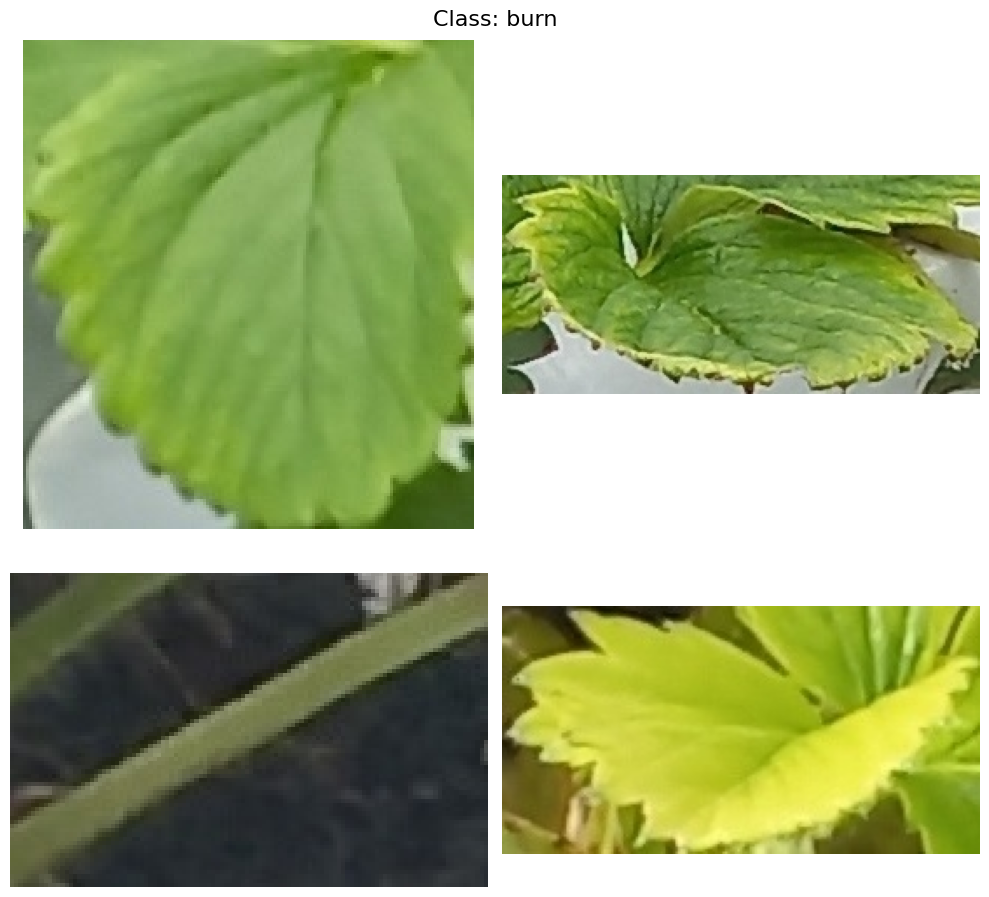

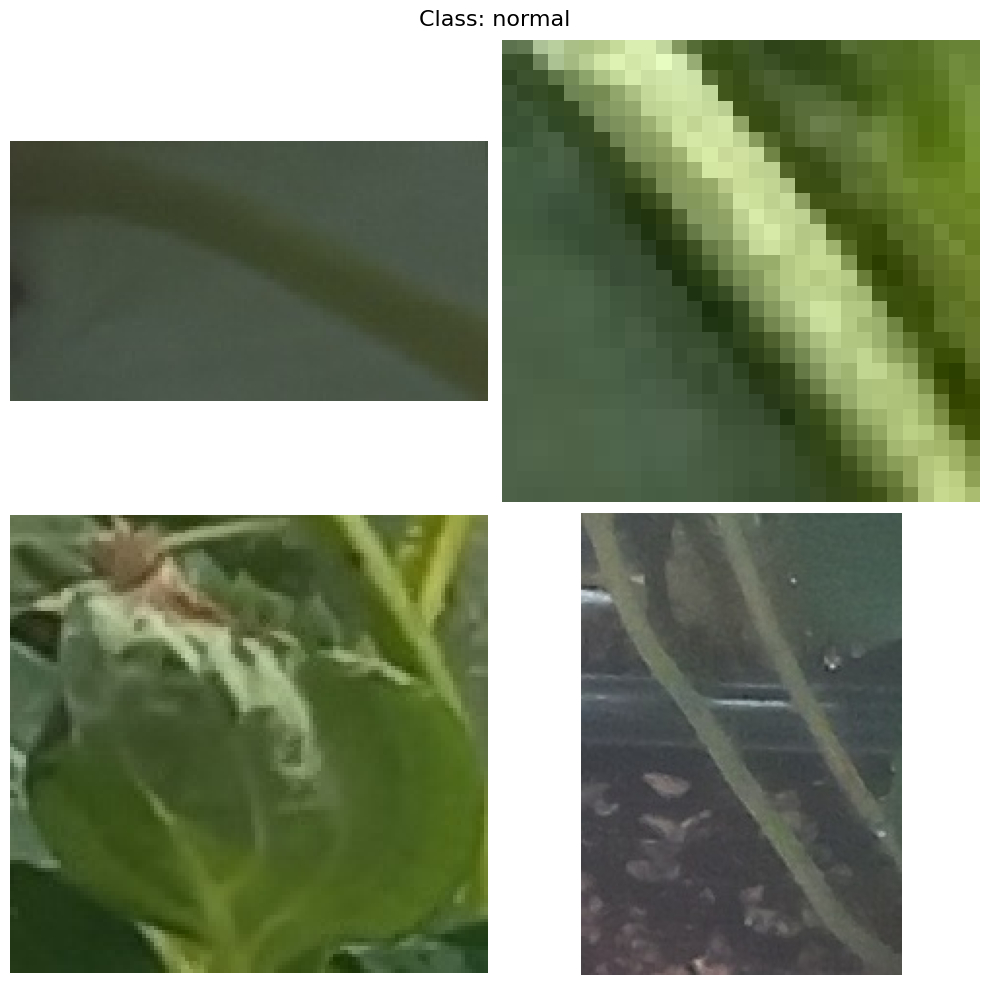

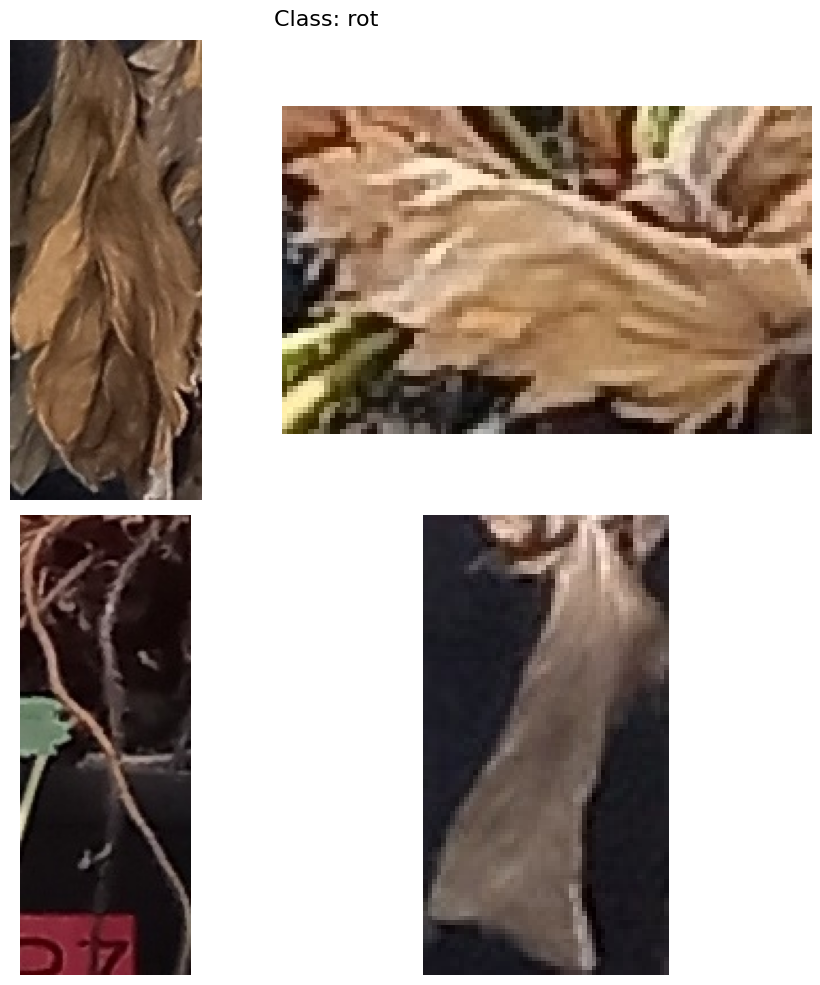

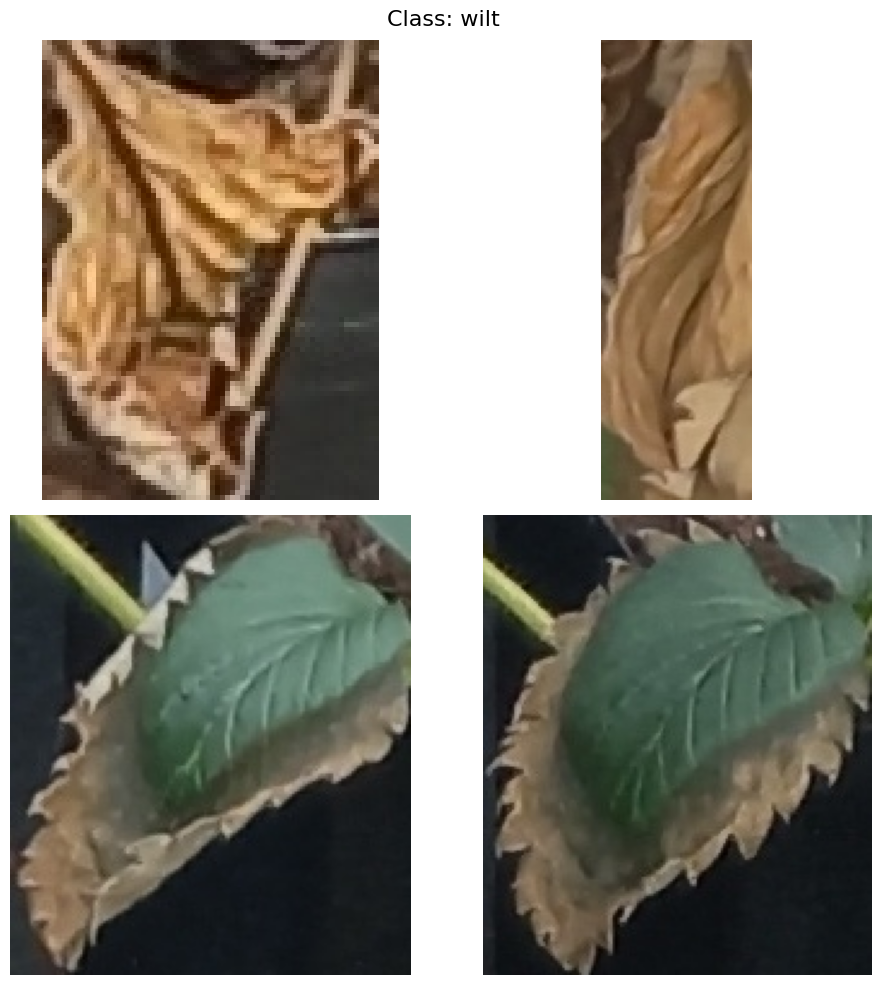

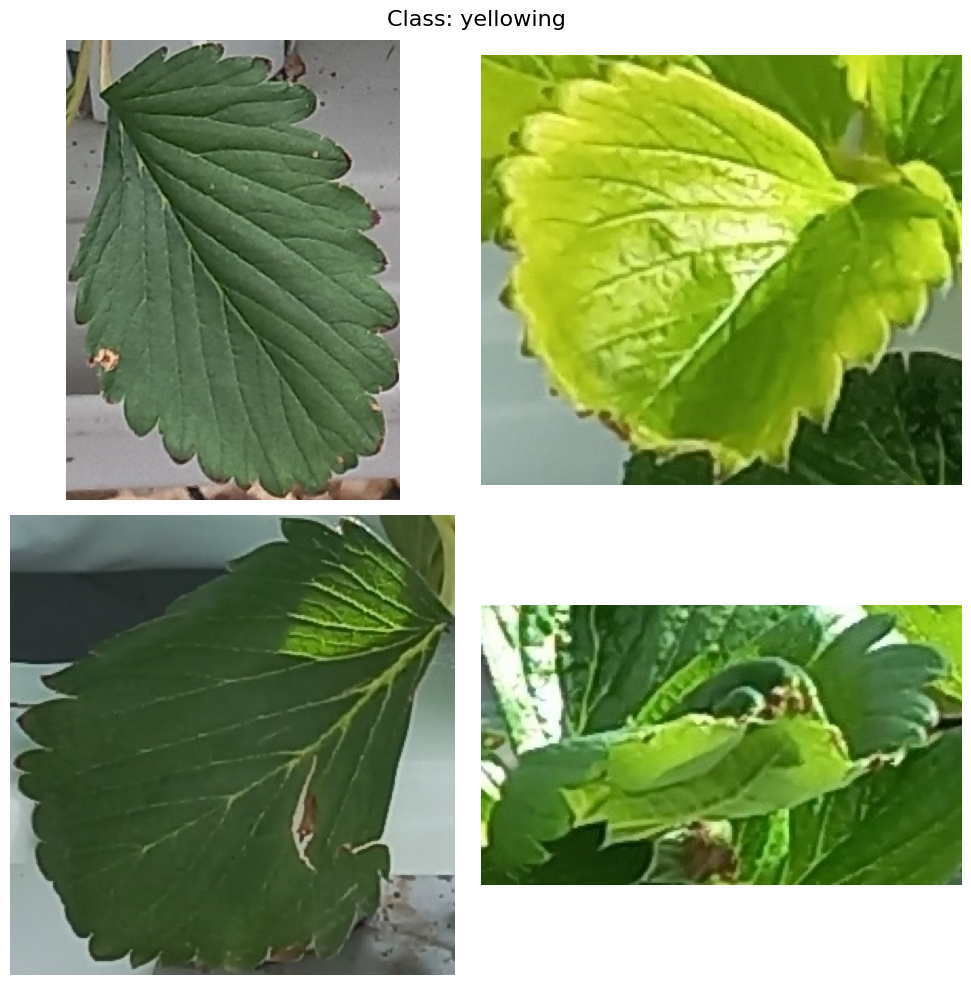

In [15]:
# import os
# import random
# import matplotlib.pyplot as plt
# from PIL import Image

# # 데이터 경로
# BASE_DIR = "/content/strawberry_classification"
# CLASSES = ["burn", "normal", "rot", "wilt", "yellowing"]

# def visualize_class_images(base_dir, classes, grid_size=5):
#     for cls in classes:
#         cls_dir = os.path.join(base_dir, cls)
#         images = [f for f in os.listdir(cls_dir) if f.lower().endswith(('.jpg', '.png', '.jpeg'))]

#         # 샘플 수 부족 시 전체 사용
#         sample_imgs = random.sample(images, min(len(images), grid_size * grid_size))

#         fig, axes = plt.subplots(grid_size, grid_size, figsize=(10, 10))
#         fig.suptitle(f"Class: {cls}", fontsize=16)

#         for i, ax in enumerate(axes.flat):
#             if i < len(sample_imgs):
#                 img_path = os.path.join(cls_dir, sample_imgs[i])
#                 img = Image.open(img_path).convert("RGB")
#                 ax.imshow(img)
#             ax.axis("off")

#         plt.tight_layout()
#         plt.show()

# # 실행
# visualize_class_images(BASE_DIR, CLASSES, grid_size=2)


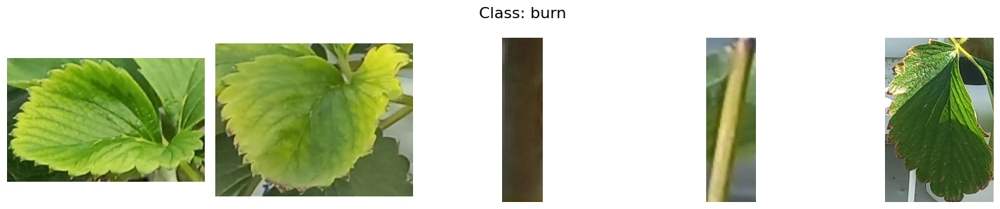

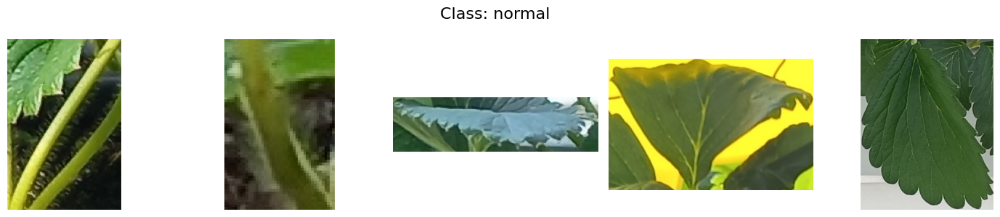

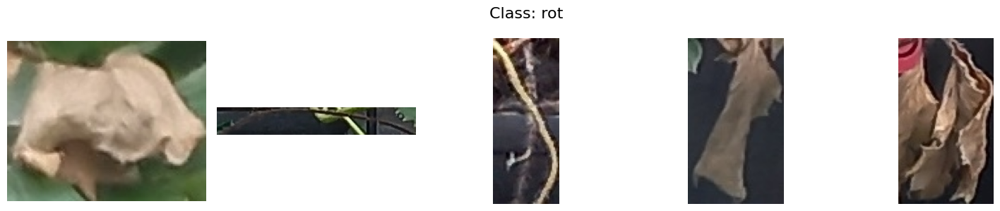

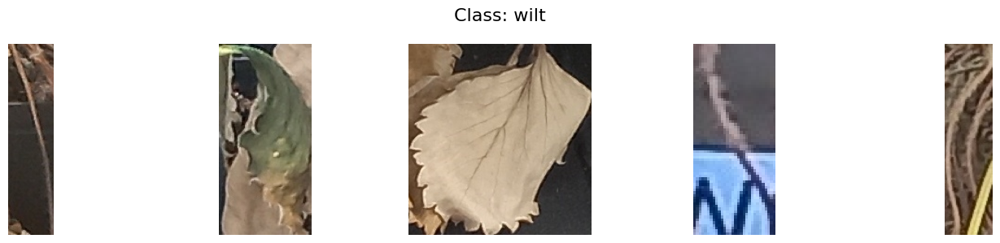

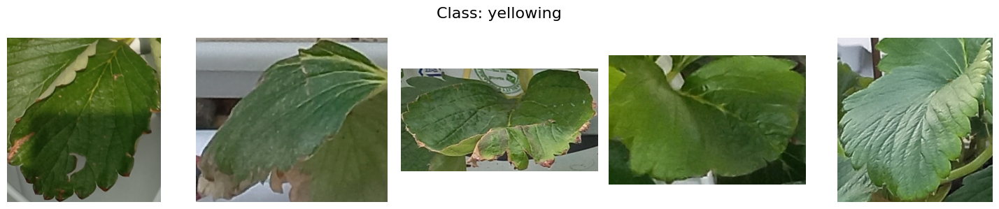

In [47]:
# def visualize_class_images(base_dir, classes, num_images=5):
#     for cls in classes:
#         cls_dir = os.path.join(base_dir, cls)
#         images = [f for f in os.listdir(cls_dir) if f.lower().endswith(('.jpg', '.png', '.jpeg'))]

#         sample_imgs = random.sample(images, min(len(images), num_images))

#         fig, axes = plt.subplots(1, num_images, figsize=(3 * num_images, 3))
#         fig.suptitle(f"Class: {cls}", fontsize=16)

#         for ax, img_name in zip(axes, sample_imgs):
#             img_path = os.path.join(cls_dir, img_name)
#             img = Image.open(img_path).convert("RGB")
#             ax.imshow(img)
#             ax.axis("off")

#         plt.tight_layout()
#         plt.show()

# visualize_class_images(BASE_DIR, CLASSES, num_images=5)

#  - disease에 가중치 추가 안 했을때!

In [ ]:
# import os
# import shutil
# from pathlib import Path
# from sklearn.model_selection import train_test_split
# from tqdm import tqdm

# # ====================================================================
# # Classification 데이터를 train/val/test로 분할
# # ====================================================================

# source_path = Path("/content/strawberry_classification")
# output_path = Path("/content/classification_split")

# # 질병 → normal/disease 매핑
# disease_mapping = {
#     'normal': 'normal',
#     'burn': 'disease',
#     'rot': 'disease',
#     'wilt': 'disease',
#     'yellowing': 'disease'
# }

# train_split = 0.8
# val_split = 0.1
# # test_split = 0.1 (나머지)

# print("="*60)
# print("📂 Classification 데이터 분할 (train/val/test)")
# print("="*60)

# # 출력 폴더 생성
# for split in ['train', 'val', 'test']:
#     for cls in ['normal', 'disease']:
#         (output_path / split / cls).mkdir(parents=True, exist_ok=True)

# # 각 질병 폴더 처리
# stats = {}

# for disease_folder in ['normal', 'burn', 'rot', 'wilt', 'yellowing']:
#     disease_path = source_path / disease_folder

#     if not disease_path.exists():
#         continue

#     # 이미지 목록
#     images = list(disease_path.glob("*.jpg"))
#     total = len(images)

#     print(f"\n{disease_folder}: {total}장")

#     # Train/Val/Test 분할
#     train_imgs, temp_imgs = train_test_split(images, train_size=train_split, random_state=42)
#     val_imgs, test_imgs = train_test_split(temp_imgs, train_size=0.5, random_state=42)

#     # 클래스 결정
#     target_class = disease_mapping[disease_folder]

#     # 복사
#     for img_list, split in [(train_imgs, 'train'), (val_imgs, 'val'), (test_imgs, 'test')]:
#         for img_path in tqdm(img_list, desc=f"  {split}", leave=False):
#             dst = output_path / split / target_class / img_path.name
#             shutil.copy(img_path, dst)

#         key = f"{split}_{target_class}"
#         stats[key] = stats.get(key, 0) + len(img_list)

# # 통계 출력
# print("\n" + "="*60)
# print("✅ 분할 완료!")
# print("="*60)

# for split in ['train', 'val', 'test']:
#     normal = stats.get(f"{split}_normal", 0)
#     disease = stats.get(f"{split}_disease", 0)
#     print(f"\n{split.upper()}:")
#     print(f"  Normal:  {normal:4d}장")
#     print(f"  Disease: {disease:4d}장")
#     print(f"  Total:   {normal + disease:4d}장")

# print(f"\n📁 저장 위치: {output_path}")

In [ ]:
# import torch
# import torch.nn as nn
# from torchvision import datasets, transforms, models
# from torch.utils.data import DataLoader
# from pathlib import Path

# # 기본 설정
# data_path = Path("/content/classification_split")
# batch_size = 32
# device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# print(f"🔥 Using device: {device}")

# # 기본 전처리만 (증강 없음)
# transform = transforms.Compose([
#     transforms.Resize((224, 224)),
#     transforms.ToTensor(),
#     transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
# ])

# # 데이터셋 로드
# train_dataset = datasets.ImageFolder(data_path / "train", transform=transform)
# val_dataset = datasets.ImageFolder(data_path / "val", transform=transform)
# test_dataset = datasets.ImageFolder(data_path / "test", transform=transform)

# # DataLoader
# train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True, num_workers=2)
# val_loader = DataLoader(val_dataset, batch_size=batch_size, shuffle=False, num_workers=2)
# test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False, num_workers=2)

# print(f"\n📊 데이터셋:")
# print(f"  Train: {len(train_dataset)}장")
# print(f"  Val:   {len(val_dataset)}장")
# print(f"  Test:  {len(test_dataset)}장")
# print(f"  Classes: {train_dataset.classes}")

# # ResNet50 모델
# model = models.resnet50(pretrained=True)
# num_features = model.fc.in_features
# model.fc = nn.Linear(num_features, 2)  # 2개 클래스
# model = model.to(device)

# print(f"\n✅ 모델 준비 완료!")

### ResNet50 모델
1 epoch -> 16분 |
Loss: 0.1810 | Val Acc: 93.95%

In [ ]:
# import torch.optim as optim
# from tqdm import tqdm

# # Loss & Optimizer
# criterion = nn.CrossEntropyLoss()
# optimizer = optim.Adam(model.parameters(), lr=0.001)

# # 학습 함수
# def train_one_epoch(model, loader, criterion, optimizer, device):
#     model.train()
#     running_loss = 0.0
#     correct = 0
#     total = 0

#     pbar = tqdm(loader, desc="Training")
#     for images, labels in pbar:
#         images, labels = images.to(device), labels.to(device)

#         optimizer.zero_grad()
#         outputs = model(images)
#         loss = criterion(outputs, labels)
#         loss.backward()
#         optimizer.step()

#         running_loss += loss.item()
#         _, predicted = outputs.max(1)
#         total += labels.size(0)
#         correct += predicted.eq(labels).sum().item()

#         pbar.set_postfix({'loss': f'{loss.item():.4f}', 'acc': f'{100.*correct/total:.2f}%'})

#     epoch_loss = running_loss / len(loader)
#     epoch_acc = 100. * correct / total
#     return epoch_loss, epoch_acc

# # 검증 함수
# def validate(model, loader, criterion, device):
#     model.eval()
#     running_loss = 0.0
#     correct = 0
#     total = 0

#     with torch.no_grad():
#         for images, labels in tqdm(loader, desc="Validation"):
#             images, labels = images.to(device), labels.to(device)
#             outputs = model(images)
#             loss = criterion(outputs, labels)

#             running_loss += loss.item()
#             _, predicted = outputs.max(1)
#             total += labels.size(0)
#             correct += predicted.eq(labels).sum().item()

#     epoch_loss = running_loss / len(loader)
#     epoch_acc = 100. * correct / total
#     return epoch_loss, epoch_acc

# print("✅ 학습 함수 준비 완료!")

In [ ]:
# print("="*60)
# print("🚀 1 에포크 테스트 시작")
# print("="*60)

# # 1 에포크 학습
# train_loss, train_acc = train_one_epoch(model, train_loader, criterion, optimizer, device)
# print(f"\nTrain Loss: {train_loss:.4f} | Train Acc: {train_acc:.2f}%")

# # 검증
# val_loss, val_acc = validate(model, val_loader, criterion, device)
# print(f"Val Loss:   {val_loss:.4f} | Val Acc:   {val_acc:.2f}%")

# print("\n✅ 1 에포크 완료!")

### EfficientNet-B0

In [ ]:
# import torch
# import torch.nn as nn
# from torchvision import datasets, transforms, models
# from torch.utils.data import DataLoader
# from pathlib import Path

# # 기본 설정
# data_path = Path("/content/classification_split")
# batch_size = 32
# device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# print(f"🔥 Using device: {device}")

# # EfficientNet 전처리 (224x224)
# transform = transforms.Compose([
#     transforms.Resize((224, 224)),
#     transforms.ToTensor(),
#     transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
# ])

# # 데이터셋 로드
# train_dataset = datasets.ImageFolder(data_path / "train", transform=transform)
# val_dataset = datasets.ImageFolder(data_path / "val", transform=transform)
# test_dataset = datasets.ImageFolder(data_path / "test", transform=transform)

# # DataLoader
# train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True, num_workers=2)
# val_loader = DataLoader(val_dataset, batch_size=batch_size, shuffle=False, num_workers=2)
# test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False, num_workers=2)

# print(f"\n📊 데이터셋:")
# print(f"  Train: {len(train_dataset)}장")
# print(f"  Val:   {len(val_dataset)}장")
# print(f"  Test:  {len(test_dataset)}장")
# print(f"  Classes: {train_dataset.classes}")

# # EfficientNet-B0 모델
# model = models.efficientnet_b0(weights='DEFAULT')
# num_features = model.classifier[1].in_features
# model.classifier[1] = nn.Linear(num_features, 2)  # 2개 클래스
# model = model.to(device)

# print(f"\n✅ EfficientNet-B0 모델 준비 완료!")

In [ ]:
# import torch.optim as optim
# from tqdm import tqdm

# # Loss & Optimizer
# criterion = nn.CrossEntropyLoss()
# optimizer = optim.Adam(model.parameters(), lr=0.001)

# # 학습 함수
# def train_one_epoch(model, loader, criterion, optimizer, device):
#     model.train()
#     running_loss = 0.0
#     correct = 0
#     total = 0

#     pbar = tqdm(loader, desc="Training")
#     for images, labels in pbar:
#         images, labels = images.to(device), labels.to(device)

#         optimizer.zero_grad()
#         outputs = model(images)
#         loss = criterion(outputs, labels)
#         loss.backward()
#         optimizer.step()

#         running_loss += loss.item()
#         _, predicted = outputs.max(1)
#         total += labels.size(0)
#         correct += predicted.eq(labels).sum().item()

#         pbar.set_postfix({'loss': f'{loss.item():.4f}', 'acc': f'{100.*correct/total:.2f}%'})

#     epoch_loss = running_loss / len(loader)
#     epoch_acc = 100. * correct / total
#     return epoch_loss, epoch_acc

# # 검증 함수
# def validate(model, loader, criterion, device):
#     model.eval()
#     running_loss = 0.0
#     correct = 0
#     total = 0

#     with torch.no_grad():
#         for images, labels in tqdm(loader, desc="Validation"):
#             images, labels = images.to(device), labels.to(device)
#             outputs = model(images)
#             loss = criterion(outputs, labels)

#             running_loss += loss.item()
#             _, predicted = outputs.max(1)
#             total += labels.size(0)
#             correct += predicted.eq(labels).sum().item()

#     epoch_loss = running_loss / len(loader)
#     epoch_acc = 100. * correct / total
#     return epoch_loss, epoch_acc

# print("✅ 학습 함수 준비 완료!")

In [ ]:
# import torch.optim as optim
# from tqdm import tqdm

# # Loss & Optimizer
# criterion = nn.CrossEntropyLoss()
# optimizer = optim.Adam(model.parameters(), lr=0.001)

# # 학습 함수
# def train_one_epoch(model, loader, criterion, optimizer, device):
#     model.train()
#     running_loss = 0.0
#     correct = 0
#     total = 0

#     pbar = tqdm(loader, desc="Training")
#     for images, labels in pbar:
#         images, labels = images.to(device), labels.to(device)

#         optimizer.zero_grad()
#         outputs = model(images)
#         loss = criterion(outputs, labels)
#         loss.backward()
#         optimizer.step()

#         running_loss += loss.item()
#         _, predicted = outputs.max(1)
#         total += labels.size(0)
#         correct += predicted.eq(labels).sum().item()

#         pbar.set_postfix({'loss': f'{loss.item():.4f}', 'acc': f'{100.*correct/total:.2f}%'})

#     epoch_loss = running_loss / len(loader)
#     epoch_acc = 100. * correct / total
#     return epoch_loss, epoch_acc

# # 검증 함수
# def validate(model, loader, criterion, device):
#     model.eval()
#     running_loss = 0.0
#     correct = 0
#     total = 0

#     with torch.no_grad():
#         for images, labels in tqdm(loader, desc="Validation"):
#             images, labels = images.to(device), labels.to(device)
#             outputs = model(images)
#             loss = criterion(outputs, labels)

#             running_loss += loss.item()
#             _, predicted = outputs.max(1)
#             total += labels.size(0)
#             correct += predicted.eq(labels).sum().item()

#     epoch_loss = running_loss / len(loader)
#     epoch_acc = 100. * correct / total
#     return epoch_loss, epoch_acc

# print("✅ 학습 함수 준비 완료!")

In [ ]:
# print("="*60)
# print("🚀 EfficientNet 1 에포크 테스트 시작")
# print("="*60)

# # 1 에포크 학습
# train_loss, train_acc = train_one_epoch(model, train_loader, criterion, optimizer, device)
# print(f"\nTrain Loss: {train_loss:.4f} | Train Acc: {train_acc:.2f}%")

# # 검증
# val_loss, val_acc = validate(model, val_loader, criterion, device)
# print(f"Val Loss:   {val_loss:.4f} | Val Acc:   {val_acc:.2f}%")

# print("\n✅ 1 에포크 완료!")

# disease에 가중치 추가 및 val / test : normal과 disease 비율 맞추기 /  f1 score 추가

## EfficientNet모델 + val/test : normal/disease 비율 맞추기

In [ ]:
import os
import shutil
from pathlib import Path
from sklearn.model_selection import train_test_split
from tqdm import tqdm
import numpy as np

# ====================================================================
# Classification 데이터를 train/val/test로 재분할
# Val/Test는 클래스 균형 맞춤
# ====================================================================

source_path = Path("/content/strawberry_classification")
output_path = Path("/content/classification_balanced")

# 질병 → normal/disease 매핑
disease_mapping = {
    'normal': 'normal',
    'burn': 'disease',
    'rot': 'disease',
    'wilt': 'disease',
    'yellowing': 'disease'
}

print("="*60)
print("📂 Classification 데이터 재분할 (Val/Test 균형)")
print("="*60)

# 출력 폴더 생성
for split in ['train', 'val', 'test']:
    for cls in ['normal', 'disease']:
        (output_path / split / cls).mkdir(parents=True, exist_ok=True)

# 각 클래스별로 이미지 수집
normal_images = []
disease_images = []

for disease_folder in ['normal', 'burn', 'rot', 'wilt', 'yellowing']:
    disease_path = source_path / disease_folder
    if not disease_path.exists():
        continue

    images = list(disease_path.glob("*.jpg"))
    target_class = disease_mapping[disease_folder]

    if target_class == 'normal':
        normal_images.extend(images)
    else:
        disease_images.extend(images)

print(f"\n전체 이미지 수:")
print(f"  Normal:  {len(normal_images)}장")
print(f"  Disease: {len(disease_images)}장")

# Train은 원래 비율대로, Val/Test는 균형있게
train_ratio = 0.8
val_test_ratio = 0.1  # 각각 10%

# Normal 분할
normal_train, normal_temp = train_test_split(normal_images, train_size=train_ratio, random_state=42)
normal_val, normal_test = train_test_split(normal_temp, train_size=0.5, random_state=42)

# Disease 분할
disease_train, disease_temp = train_test_split(disease_images, train_size=train_ratio, random_state=42)
disease_val, disease_test = train_test_split(disease_temp, train_size=0.5, random_state=42)

# Val/Test를 균형있게 조정 (더 적은 클래스에 맞춤)
val_min = min(len(normal_val), len(disease_val))
test_min = min(len(normal_test), len(disease_test))

normal_val = normal_val[:val_min]
disease_val = disease_val[:val_min]
normal_test = normal_test[:test_min]
disease_test = disease_test[:test_min]

print(f"\n분할 결과:")
print(f"\nTRAIN (원래 비율):")
print(f"  Normal:  {len(normal_train)}장")
print(f"  Disease: {len(disease_train)}장")
print(f"  Total:   {len(normal_train) + len(disease_train)}장")

print(f"\nVAL (균형):")
print(f"  Normal:  {len(normal_val)}장")
print(f"  Disease: {len(disease_val)}장")
print(f"  Total:   {len(normal_val) + len(disease_val)}장")

print(f"\nTEST (균형):")
print(f"  Normal:  {len(normal_test)}장")
print(f"  Disease: {len(disease_test)}장")
print(f"  Total:   {len(normal_test) + len(disease_test)}장")

# 파일 복사
splits = {
    'train': {'normal': normal_train, 'disease': disease_train},
    'val': {'normal': normal_val, 'disease': disease_val},
    'test': {'normal': normal_test, 'disease': disease_test}
}

for split_name, classes in splits.items():
    for class_name, img_list in classes.items():
        for img_path in tqdm(img_list, desc=f"{split_name}/{class_name}"):
            dst = output_path / split_name / class_name / img_path.name
            shutil.copy(img_path, dst)

print(f"\n✅ 분할 완료!")
print(f"📁 저장 위치: {output_path}")

📂 Classification 데이터 재분할 (Val/Test 균형)

전체 이미지 수:
  Normal:  110020장
  Disease: 16507장

분할 결과:

TRAIN (원래 비율):
  Normal:  88016장
  Disease: 13205장
  Total:   101221장

VAL (균형):
  Normal:  1651장
  Disease: 1651장
  Total:   3302장

TEST (균형):
  Normal:  1651장
  Disease: 1651장
  Total:   3302장


test/disease: 100%|██████████| 1651/1651 [00:00<00:00, 7107.17it/s]


✅ 분할 완료!
📁 저장 위치: /content/classification_balanced


In [ ]:
import torch
import torch.nn as nn
from torchvision import datasets, transforms, models
from torch.utils.data import DataLoader
from pathlib import Path

# 새로운 데이터 경로
data_path = Path("/content/classification_balanced")
batch_size = 128
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print(f"🔥 Using device: {device}")

# 전처리
transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

# 데이터셋 로드
train_dataset = datasets.ImageFolder(data_path / "train", transform=transform)
val_dataset = datasets.ImageFolder(data_path / "val", transform=transform)
test_dataset = datasets.ImageFolder(data_path / "test", transform=transform)

# DataLoader
train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True, num_workers=2)
val_loader = DataLoader(val_dataset, batch_size=batch_size, shuffle=False, num_workers=2)
test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False, num_workers=2)

print(f"\n📊 데이터셋:")
print(f"  Train: {len(train_dataset)}장 (불균형)")
print(f"  Val:   {len(val_dataset)}장 (균형)")
print(f"  Test:  {len(test_dataset)}장 (균형)")
print(f"  Classes: {train_dataset.classes}")

# EfficientNet-B0 모델
model = models.efficientnet_b0(weights='DEFAULT')
num_features = model.classifier[1].in_features
model.classifier[1] = nn.Linear(num_features, 2)
model = model.to(device)

# 클래스 가중치 계산
class_counts = [len([s for s in train_dataset.samples if s[1] == i]) for i in range(2)]
print(f"\nTrain 클래스별 샘플 수: {dict(zip(train_dataset.classes, class_counts))}")

class_weights = 1.0 / torch.tensor(class_counts, dtype=torch.float)
class_weights = class_weights / class_weights.sum() * 2
class_weights = class_weights.to(device)

print(f"클래스 가중치: {dict(zip(train_dataset.classes, class_weights.cpu().numpy()))}")

print(f"\n✅ 모델 준비 완료!")

🔥 Using device: cuda

📊 데이터셋:
  Train: 96938장 (불균형)
  Val:   3226장 (균형)
  Test:  3214장 (균형)
  Classes: ['disease', 'normal']
Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b0_rwightman-7f5810bc.pth


100%|██████████| 20.5M/20.5M [00:00<00:00, 49.0MB/s]



Train 클래스별 샘플 수: {'disease': 8922, 'normal': 88016}
클래스 가중치: {'disease': np.float32(1.8159236), 'normal': np.float32(0.18407641)}

✅ 모델 준비 완료!


In [ ]:
import torch.optim as optim
from tqdm import tqdm
from sklearn.metrics import f1_score, precision_score, recall_score
import numpy as np

# Loss & Optimizer
criterion = nn.CrossEntropyLoss(weight=class_weights)
optimizer = optim.Adam(model.parameters(), lr=0.001)

# 학습 함수
def train_one_epoch(model, loader, criterion, optimizer, device):
    model.train()
    running_loss = 0.0
    correct = 0
    total = 0

    pbar = tqdm(loader, desc="Training")
    for images, labels in pbar:
        images, labels = images.to(device), labels.to(device)

        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        running_loss += loss.item()
        _, predicted = outputs.max(1)
        total += labels.size(0)
        correct += predicted.eq(labels).sum().item()

        pbar.set_postfix({'loss': f'{loss.item():.4f}', 'acc': f'{100.*correct/total:.2f}%'})

    epoch_loss = running_loss / len(loader)
    epoch_acc = 100. * correct / total
    return epoch_loss, epoch_acc

# 검증 함수 (F1-score 포함)
def validate(model, loader, criterion, device):
    model.eval()
    running_loss = 0.0
    all_preds = []
    all_labels = []

    with torch.no_grad():
        for images, labels in tqdm(loader, desc="Validation"):
            images, labels = images.to(device), labels.to(device)
            outputs = model(images)
            loss = criterion(outputs, labels)

            running_loss += loss.item()
            _, predicted = outputs.max(1)

            all_preds.extend(predicted.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())

    epoch_loss = running_loss / len(loader)
    epoch_acc = 100. * np.sum(np.array(all_preds) == np.array(all_labels)) / len(all_labels)

    # F1, Precision, Recall 계산
    f1 = f1_score(all_labels, all_preds, average='weighted')
    precision = precision_score(all_labels, all_preds, average='weighted')
    recall = recall_score(all_labels, all_preds, average='weighted')

    return epoch_loss, epoch_acc, f1, precision, recall

print("✅ 학습 함수 준비 완료!")

✅ 학습 함수 준비 완료!


In [ ]:
print("="*60)
print("🚀 1 에포크 테스트 시작 (클래스 가중치 적용)")
print("="*60)

# 1 에포크 학습
train_loss, train_acc = train_one_epoch(model, train_loader, criterion, optimizer, device)
print(f"\nTrain Loss: {train_loss:.4f} | Train Acc: {train_acc:.2f}%")

# 검증 (F1-score 포함)
val_loss, val_acc, val_f1, val_precision, val_recall = validate(model, val_loader, criterion, device)
print(f"Val Loss:      {val_loss:.4f}")
print(f"Val Acc:       {val_acc:.2f}%")
print(f"Val F1:        {val_f1:.4f}")
print(f"Val Precision: {val_precision:.4f}")
print(f"Val Recall:    {val_recall:.4f}")

print("\n✅ 1 에포크 완료!")

🚀 1 에포크 테스트 시작 (클래스 가중치 적용)


Training:   6%|▋         | 48/758 [00:22<05:33,  2.13it/s, loss=0.6098, acc=87.00%]


KeyboardInterrupt: 

In [ ]:
num_epochs = 100  # 최대 에포크 (Early Stopping으로 일찍 끝날 수 있음)
patience = 10  # 3 에포크 동안 개선 없으면 중단

history = {
    'train_loss': [], 'train_acc': [],
    'val_loss': [], 'val_acc': [],
    'val_f1': [], 'val_precision': [], 'val_recall': []
}

best_val_f1 = 0.0
patience_counter = 0

print("="*60)
print(f"🚀 전체 학습 시작 (Early Stopping: patience={patience})")
print("="*60)

for epoch in range(num_epochs):
    print(f"\n📍 Epoch [{epoch+1}/{num_epochs}]")

    # 학습
    train_loss, train_acc = train_one_epoch(model, train_loader, criterion, optimizer, device)

    # 검증
    val_loss, val_acc, val_f1, val_precision, val_recall = validate(model, val_loader, criterion, device)

    # 기록
    history['train_loss'].append(train_loss)
    history['train_acc'].append(train_acc)
    history['val_loss'].append(val_loss)
    history['val_acc'].append(val_acc)
    history['val_f1'].append(val_f1)
    history['val_precision'].append(val_precision)
    history['val_recall'].append(val_recall)

    print(f"  Train Loss: {train_loss:.4f} | Train Acc: {train_acc:.2f}%")
    print(f"  Val Loss:   {val_loss:.4f} | Val Acc:   {val_acc:.2f}%")
    print(f"  Val F1:     {val_f1:.4f} | Precision: {val_precision:.4f} | Recall: {val_recall:.4f}")

    # Best 모델 저장 및 Early Stopping 체크
    if val_f1 > best_val_f1:
        best_val_f1 = val_f1
        patience_counter = 0
        torch.save(model.state_dict(), '/content/best_efficientnet_balanced.pth')
        print(f"  ✅ Best model saved! (Val F1: {val_f1:.4f})")
    else:
        patience_counter += 1
        print(f"  ⏳ No improvement ({patience_counter}/{patience})")

        if patience_counter >= patience:
            print(f"\n🛑 Early Stopping! No improvement for {patience} epochs.")
            break

print("\n" + "="*60)
print("✅ 학습 완료!")
print(f"🏆 Best Validation F1-score: {best_val_f1:.4f}")
print(f"📊 Total Epochs: {epoch+1}")
print("="*60)

🚀 전체 학습 시작 (Early Stopping: patience=10)

📍 Epoch [1/100]


Validation: 100%|██████████| 26/26 [00:04<00:00,  5.91it/s]


  Train Loss: 0.2114 | Train Acc: 93.98%
  Val Loss:   0.2078 | Val Acc:   92.37%
  Val F1:     0.9237 | Precision: 0.9243 | Recall: 0.9237
  ✅ Best model saved! (Val F1: 0.9237)

📍 Epoch [2/100]


Validation: 100%|██████████| 26/26 [00:04<00:00,  5.98it/s]


  Train Loss: 0.1701 | Train Acc: 94.81%
  Val Loss:   0.1964 | Val Acc:   93.18%
  Val F1:     0.9318 | Precision: 0.9320 | Recall: 0.9318
  ✅ Best model saved! (Val F1: 0.9318)

📍 Epoch [3/100]


Validation: 100%|██████████| 26/26 [00:04<00:00,  5.87it/s]


... (15 outputs left out)

Validation: 100%|██████████| 26/26 [00:04<00:00,  5.62it/s]


  Train Loss: 0.0670 | Train Acc: 97.40%
  Val Loss:   0.3992 | Val Acc:   92.31%
  Val F1:     0.9229 | Precision: 0.9271 | Recall: 0.9231
  ⏳ No improvement (9/10)

📍 Epoch [12/100]


Validation: 100%|██████████| 26/26 [00:04<00:00,  5.91it/s]

  Train Loss: 0.0568 | Train Acc: 97.79%
  Val Loss:   0.3756 | Val Acc:   92.68%
  Val F1:     0.9267 | Precision: 0.9288 | Recall: 0.9268
  ⏳ No improvement (10/10)

🛑 Early Stopping! No improvement for 10 epochs.

✅ 학습 완료!
🏆 Best Validation F1-score: 0.9318
📊 Total Epochs: 12


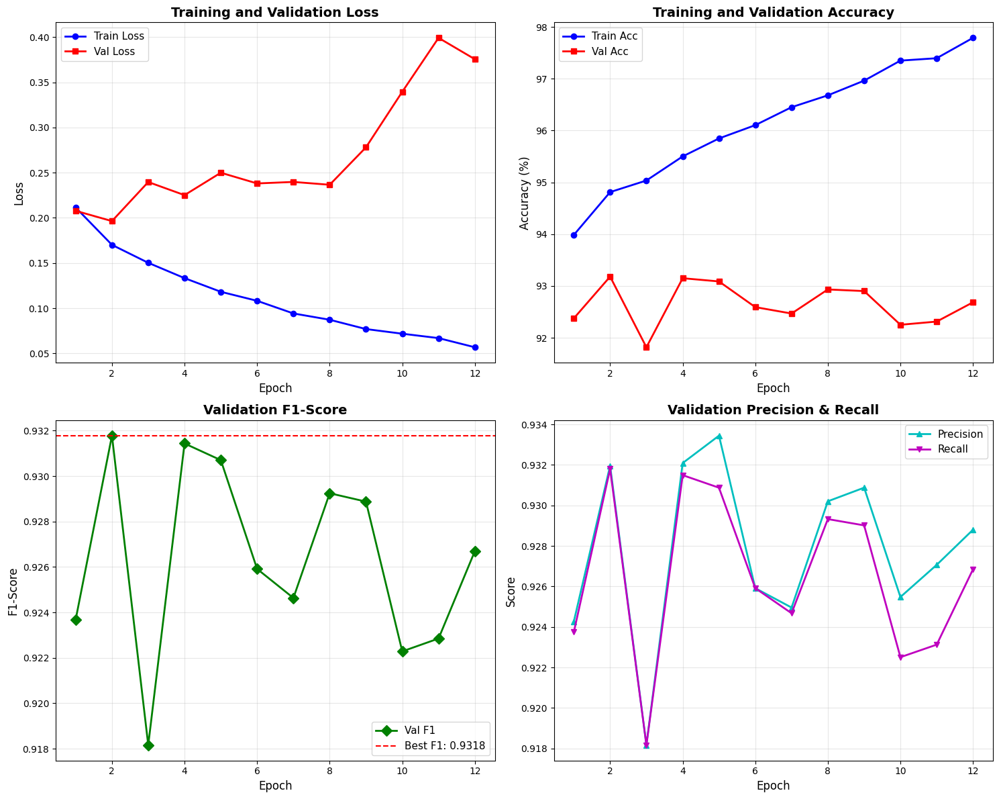

✅ 학습 그래프 저장 완료: /content/training_history.png


In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix, classification_report
import numpy as np

# ====================================================================
# 1. 학습 그래프
# ====================================================================

fig, axes = plt.subplots(2, 2, figsize=(15, 12))

epochs = range(1, len(history['train_loss']) + 1)

# Loss
axes[0, 0].plot(epochs, history['train_loss'], 'b-o', label='Train Loss', linewidth=2)
axes[0, 0].plot(epochs, history['val_loss'], 'r-s', label='Val Loss', linewidth=2)
axes[0, 0].set_xlabel('Epoch', fontsize=12)
axes[0, 0].set_ylabel('Loss', fontsize=12)
axes[0, 0].set_title('Training and Validation Loss', fontsize=14, fontweight='bold')
axes[0, 0].legend(fontsize=11)
axes[0, 0].grid(True, alpha=0.3)

# Accuracy
axes[0, 1].plot(epochs, history['train_acc'], 'b-o', label='Train Acc', linewidth=2)
axes[0, 1].plot(epochs, history['val_acc'], 'r-s', label='Val Acc', linewidth=2)
axes[0, 1].set_xlabel('Epoch', fontsize=12)
axes[0, 1].set_ylabel('Accuracy (%)', fontsize=12)
axes[0, 1].set_title('Training and Validation Accuracy', fontsize=14, fontweight='bold')
axes[0, 1].legend(fontsize=11)
axes[0, 1].grid(True, alpha=0.3)

# F1-Score
axes[1, 0].plot(epochs, history['val_f1'], 'g-D', label='Val F1', linewidth=2, markersize=8)
axes[1, 0].axhline(y=best_val_f1, color='r', linestyle='--', label=f'Best F1: {best_val_f1:.4f}')
axes[1, 0].set_xlabel('Epoch', fontsize=12)
axes[1, 0].set_ylabel('F1-Score', fontsize=12)
axes[1, 0].set_title('Validation F1-Score', fontsize=14, fontweight='bold')
axes[1, 0].legend(fontsize=11)
axes[1, 0].grid(True, alpha=0.3)

# Precision & Recall
axes[1, 1].plot(epochs, history['val_precision'], 'c-^', label='Precision', linewidth=2)
axes[1, 1].plot(epochs, history['val_recall'], 'm-v', label='Recall', linewidth=2)
axes[1, 1].set_xlabel('Epoch', fontsize=12)
axes[1, 1].set_ylabel('Score', fontsize=12)
axes[1, 1].set_title('Validation Precision & Recall', fontsize=14, fontweight='bold')
axes[1, 1].legend(fontsize=11)
axes[1, 1].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('/content/training_history.png', dpi=150, bbox_inches='tight')
plt.show()

print("✅ 학습 그래프 저장 완료: /content/training_history.png")

In [ ]:
# ====================================================================
# 2. Test 데이터 평가
# ====================================================================

print("="*60)
print("🧪 Test 데이터 평가 중...")
print("="*60)

# Best 모델 로드
model.load_state_dict(torch.load('/content/best_efficientnet_balanced.pth'))
model.eval()

all_preds = []
all_labels = []
all_probs = []

with torch.no_grad():
    for images, labels in tqdm(test_loader, desc="Testing"):
        images = images.to(device)
        outputs = model(images)
        probs = torch.softmax(outputs, dim=1)
        _, predicted = outputs.max(1)

        all_preds.extend(predicted.cpu().numpy())
        all_labels.extend(labels.numpy())
        all_probs.extend(probs.cpu().numpy())

# 정확도 계산
test_acc = 100. * np.sum(np.array(all_preds) == np.array(all_labels)) / len(all_labels)
test_f1 = f1_score(all_labels, all_preds, average='weighted')
test_precision = precision_score(all_labels, all_preds, average='weighted')
test_recall = recall_score(all_labels, all_preds, average='weighted')

print(f"\n🎯 Test 결과:")
print(f"  Accuracy:  {test_acc:.2f}%")
print(f"  F1-Score:  {test_f1:.4f}")
print(f"  Precision: {test_precision:.4f}")
print(f"  Recall:    {test_recall:.4f}")

# Classification Report
print("\n" + "="*60)
print("📋 Classification Report (Test Set):")
print("="*60)
print(classification_report(all_labels, all_preds,
                          target_names=test_dataset.classes,
                          digits=4))

🧪 Test 데이터 평가 중...


Testing: 100%|██████████| 26/26 [00:04<00:00,  5.99it/s]


🎯 Test 결과:
  Accuracy:  93.62%
  F1-Score:  0.9362
  Precision: 0.9367
  Recall:    0.9362

📋 Classification Report (Test Set):
              precision    recall  f1-score   support

     disease     0.9515    0.9155    0.9332      1563
      normal     0.9228    0.9558    0.9390      1651

    accuracy                         0.9362      3214
   macro avg     0.9371    0.9357    0.9361      3214
weighted avg     0.9367    0.9362    0.9362      3214



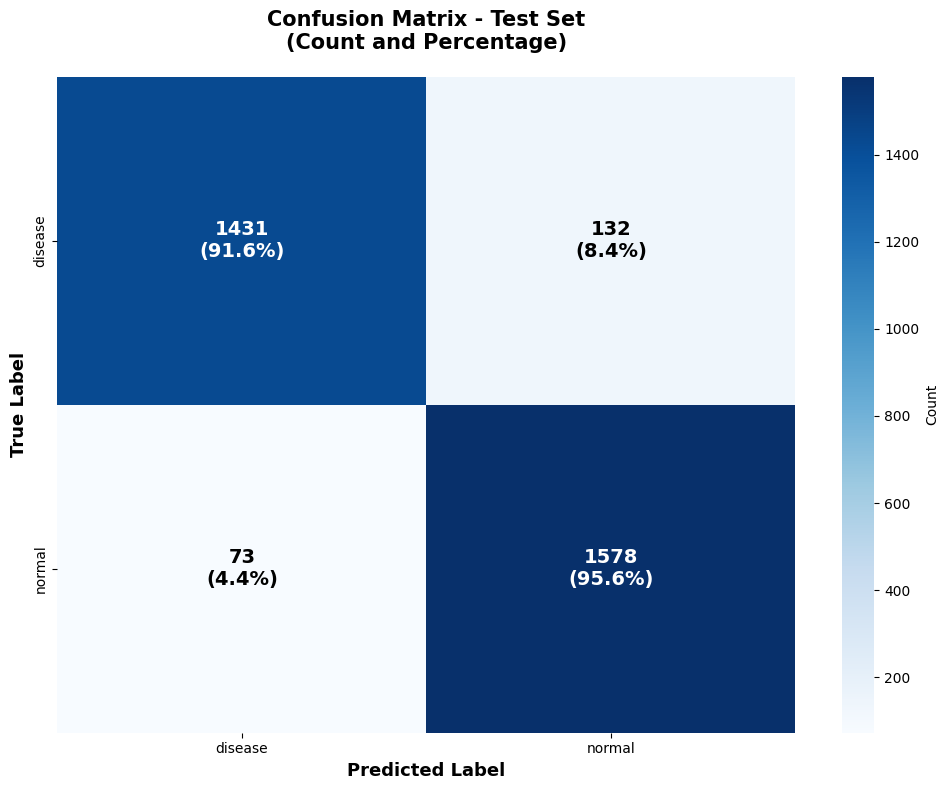

✅ Confusion Matrix 저장 완료: /content/confusion_matrix.png


In [ ]:
# ====================================================================
# 3. Confusion Matrix (개수 + 비율)
# ====================================================================

# Confusion Matrix 계산
cm = confusion_matrix(all_labels, all_preds)
cm_normalized = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis]

# 시각화
fig, ax = plt.subplots(figsize=(10, 8))

# 히트맵
sns.heatmap(cm, annot=False, fmt='d', cmap='Blues',
            xticklabels=test_dataset.classes,
            yticklabels=test_dataset.classes,
            cbar_kws={'label': 'Count'},
            ax=ax)

# 각 셀에 개수와 비율 추가
for i in range(len(cm)):
    for j in range(len(cm)):
        count = cm[i, j]
        percentage = cm_normalized[i, j] * 100
        text_color = 'white' if cm_normalized[i, j] > 0.5 else 'black'
        ax.text(j + 0.5, i + 0.5, f'{count}\n({percentage:.1f}%)',
                ha='center', va='center',
                color=text_color, fontsize=14, fontweight='bold')

ax.set_xlabel('Predicted Label', fontsize=13, fontweight='bold')
ax.set_ylabel('True Label', fontsize=13, fontweight='bold')
ax.set_title('Confusion Matrix - Test Set\n(Count and Percentage)',
             fontsize=15, fontweight='bold', pad=20)

plt.tight_layout()
plt.savefig('/content/confusion_matrix.png', dpi=150, bbox_inches='tight')
plt.show()

print("✅ Confusion Matrix 저장 완료: /content/confusion_matrix.png")

/tmp/ipython-input-3217582112.py:88: UserWarning: Glyph 50696 (\N{HANGUL SYLLABLE YE}) missing from font(s) DejaVu Sans.
  plt.savefig('/content/prediction_samples.png', dpi=150, bbox_inches='tight')
/tmp/ipython-input-3217582112.py:88: UserWarning: Glyph 52769 (\N{HANGUL SYLLABLE CEUG}) missing from font(s) DejaVu Sans.
  plt.savefig('/content/prediction_samples.png', dpi=150, bbox_inches='tight')
/tmp/ipython-input-3217582112.py:88: UserWarning: Glyph 44208 (\N{HANGUL SYLLABLE GYEOL}) missing from font(s) DejaVu Sans.
  plt.savefig('/content/prediction_samples.png', dpi=150, bbox_inches='tight')
/tmp/ipython-input-3217582112.py:88: UserWarning: Glyph 44284 (\N{HANGUL SYLLABLE GWA}) missing from font(s) DejaVu Sans.
  plt.savefig('/content/prediction_samples.png', dpi=150, bbox_inches='tight')
/tmp/ipython-input-3217582112.py:88: UserWarning: Glyph 49368 (\N{HANGUL SYLLABLE SAEM}) missing from font(s) DejaVu Sans.
  plt.savefig('/content/prediction_samples.png', dpi=150, bbox_inches='

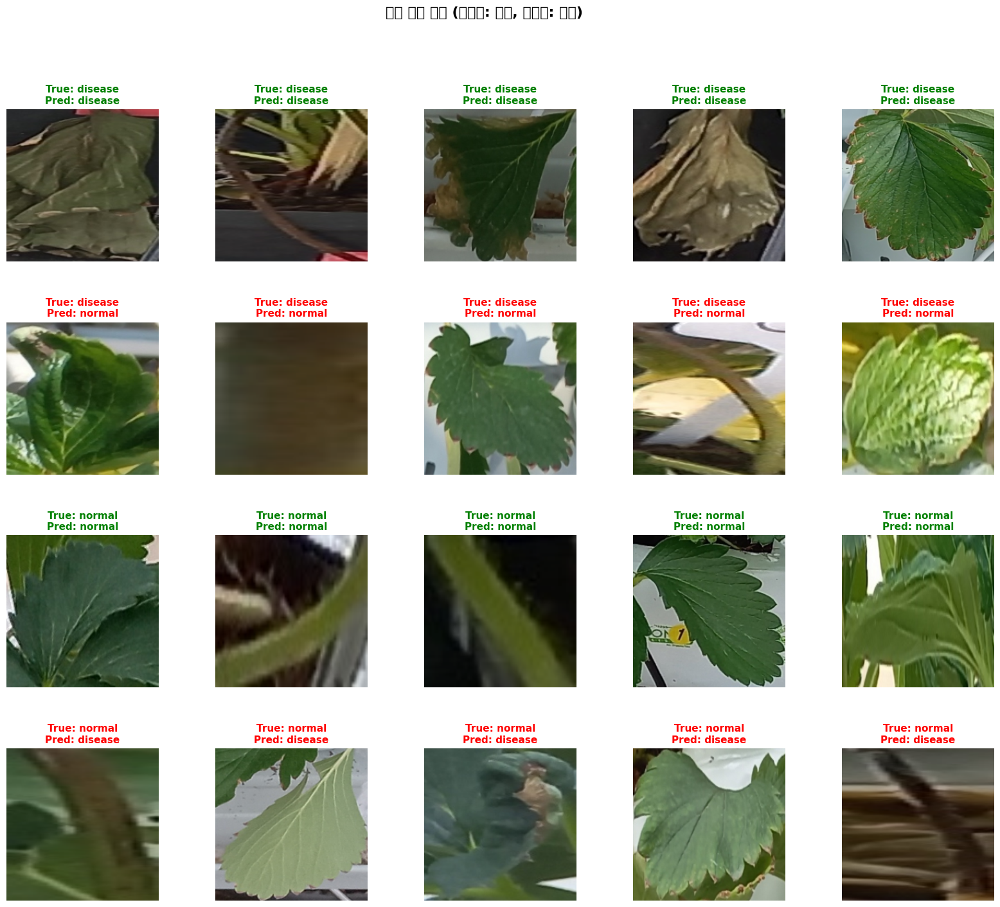

✅ 예측 샘플 시각화 저장 완료: /content/prediction_samples.png


In [ ]:
# ====================================================================
# 4. 예측 결과 샘플 시각화 (True/Pred 라벨 포함)
# ====================================================================

# 샘플 수집
model.eval()
correct_samples = {'disease': [], 'normal': []}
wrong_samples = {'disease': [], 'normal': []}

with torch.no_grad():
    for images, labels in test_loader:
        images_device = images.to(device)
        outputs = model(images_device)
        _, predicted = outputs.max(1)

        for i in range(len(labels)):
            true_label = labels[i].item()
            pred_label = predicted[i].item()
            true_class = test_dataset.classes[true_label]
            pred_class = test_dataset.classes[pred_label]

            sample = {
                'image': images[i],
                'true_label': true_class,
                'pred_label': pred_class
            }

            if true_label == pred_label:
                if len(correct_samples[true_class]) < 5:
                    correct_samples[true_class].append(sample)
            else:
                if len(wrong_samples[true_class]) < 5:
                    wrong_samples[true_class].append(sample)

            # 충분히 모았으면 종료
            if all(len(correct_samples[c]) >= 5 for c in test_dataset.classes) and \
               all(len(wrong_samples[c]) >= 5 for c in test_dataset.classes):
                break

        if all(len(correct_samples[c]) >= 5 for c in test_dataset.classes) and \
           all(len(wrong_samples[c]) >= 5 for c in test_dataset.classes):
            break

# 시각화
fig = plt.figure(figsize=(20, 16))
gs = fig.add_gridspec(4, 5, hspace=0.4, wspace=0.3)

row_titles = ['Disease - Correct ✅', 'Disease - Wrong ❌',
              'Normal - Correct ✅', 'Normal - Wrong ❌']
samples_list = [
    correct_samples['disease'],
    wrong_samples['disease'],
    correct_samples['normal'],
    wrong_samples['normal']
]

for row_idx, (title, samples) in enumerate(zip(row_titles, samples_list)):
    for col_idx, sample in enumerate(samples[:5]):
        ax = fig.add_subplot(gs[row_idx, col_idx])

        # 이미지 denormalize
        img = sample['image'].permute(1, 2, 0).numpy()
        mean = np.array([0.485, 0.456, 0.406])
        std = np.array([0.229, 0.224, 0.225])
        img = std * img + mean
        img = np.clip(img, 0, 1)

        ax.imshow(img)
        ax.axis('off')

        # 라벨 색상 설정
        if sample['true_label'] == sample['pred_label']:
            color = 'green'
        else:
            color = 'red'

        # 텍스트 추가
        title_text = f"True: {sample['true_label']}\nPred: {sample['pred_label']}"
        ax.set_title(title_text, fontsize=11, fontweight='bold', color=color)

    # 행 제목
    if col_idx == 0:
        ax.text(-0.3, 0.5, title, transform=ax.transAxes,
                fontsize=14, fontweight='bold', va='center', rotation=90)

plt.suptitle('예측 결과 샘플 (조록색: 정답, 빨간색: 오답)',
             fontsize=16, fontweight='bold', y=0.98)
plt.savefig('/content/prediction_samples.png', dpi=150, bbox_inches='tight')
plt.show()

print("✅ 예측 샘플 시각화 저장 완료: /content/prediction_samples.png")

# classfication 최종 모델 - 각 질병 클래스마다 모델 학습
이전 코드들은 다 무시하고 이 코드만 보기

In [4]:
import os
import shutil
from pathlib import Path
from sklearn.model_selection import train_test_split
from tqdm import tqdm
import numpy as np

# ====================================================================
# 5-Class Classification 데이터 분할
# ====================================================================

source_path = Path("/content/strawberry_classification")
output_path = Path("/content/classification_5class")

# 5개 클래스
classes = ['normal', 'burn', 'rot', 'wilt', 'yellowing']

train_ratio = 0.8

print("="*60)
print("📂 5-Class Classification 데이터 분할")
print("="*60)

# 출력 폴더 생성
for split in ['train', 'val', 'test']:
    for cls in classes:
        (output_path / split / cls).mkdir(parents=True, exist_ok=True)

# 각 클래스별 이미지 수집 및 분할
all_stats = {}

for cls in classes:
    cls_path = source_path / cls

    if not cls_path.exists():
        print(f"⚠️  {cls} 폴더를 찾을 수 없습니다!")
        continue

    images = list(cls_path.glob("*.jpg"))
    total = len(images)

    print(f"\n{cls}: {total}장")

    # Train/Val/Test 분할
    train_imgs, temp_imgs = train_test_split(images, train_size=train_ratio, random_state=42)
    val_imgs, test_imgs = train_test_split(temp_imgs, train_size=0.5, random_state=42)

    # Val/Test 균형 맞추기 위한 최소값 저장
    all_stats[cls] = {
        'train': train_imgs,
        'val': val_imgs,
        'test': test_imgs
    }

    print(f"  Train: {len(train_imgs)}장")
    print(f"  Val:   {len(val_imgs)}장")
    print(f"  Test:  {len(test_imgs)}장")

# Val/Test 균형 맞추기
val_min = min(len(all_stats[cls]['val']) for cls in classes)
test_min = min(len(all_stats[cls]['test']) for cls in classes)

print("\n" + "="*60)
print(f"Val/Test 균형 조정: 각 클래스당 Val={val_min}장, Test={test_min}장")
print("="*60)

# 파일 복사
for cls in classes:
    # Train (원본 비율)
    for img_path in tqdm(all_stats[cls]['train'], desc=f"train/{cls}"):
        dst = output_path / 'train' / cls / img_path.name
        shutil.copy(img_path, dst)

    # Val (균형)
    for img_path in tqdm(all_stats[cls]['val'][:val_min], desc=f"val/{cls}"):
        dst = output_path / 'val' / cls / img_path.name
        shutil.copy(img_path, dst)

    # Test (균형)
    for img_path in tqdm(all_stats[cls]['test'][:test_min], desc=f"test/{cls}"):
        dst = output_path / 'test' / cls / img_path.name
        shutil.copy(img_path, dst)

# 최종 통계
print("\n" + "="*60)
print("✅ 분할 완료!")
print("="*60)

for split in ['train', 'val', 'test']:
    print(f"\n{split.upper()}:")
    total = 0
    for cls in classes:
        count = len(list((output_path / split / cls).glob("*.jpg")))
        print(f"  {cls:10s}: {count:5d}장")
        total += count
    print(f"  {'Total':10s}: {total:5d}장")

print(f"\n📁 저장 위치: {output_path}")

📂 5-Class Classification 데이터 분할

normal: 110020장
  Train: 88016장
  Val:   11002장
  Test:  11002장

burn: 980장
  Train: 784장
  Val:   98장
  Test:  98장

rot: 4519장
  Train: 3615장
  Val:   452장
  Test:  452장

wilt: 10207장
  Train: 8165장
  Val:   1021장
  Test:  1021장

yellowing: 801장
  Train: 640장
  Val:   80장
  Test:  81장

Val/Test 균형 조정: 각 클래스당 Val=80장, Test=81장


test/yellowing: 100%|██████████| 81/81 [00:00<00:00, 7322.43it/s]



✅ 분할 완료!

TRAIN:
  normal    : 88016장
  burn      :   784장
  rot       :  3615장
  wilt      :  8165장
  yellowing :   640장
  Total     : 101220장

VAL:
  normal    :    80장
  burn      :    80장
  rot       :    80장
  wilt      :    80장
  yellowing :    80장
  Total     :   400장

TEST:
  normal    :    81장
  burn      :    81장
  rot       :    81장
  wilt      :    81장
  yellowing :    81장
  Total     :   405장

📁 저장 위치: /content/classification_5class


In [5]:
import torch
import torch.nn as nn
from torchvision import datasets, transforms, models
from torch.utils.data import DataLoader
from pathlib import Path

# 새로운 데이터 경로
data_path = Path("/content/classification_5class")
batch_size = 32
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print(f"🔥 Using device: {device}")

# 전처리
transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

# 데이터셋 로드
train_dataset = datasets.ImageFolder(data_path / "train", transform=transform)
val_dataset = datasets.ImageFolder(data_path / "val", transform=transform)
test_dataset = datasets.ImageFolder(data_path / "test", transform=transform)

# DataLoader
train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True, num_workers=2)
val_loader = DataLoader(val_dataset, batch_size=batch_size, shuffle=False, num_workers=2)
test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False, num_workers=2)

print(f"\n📊 데이터셋:")
print(f"  Train: {len(train_dataset)}장")
print(f"  Val:   {len(val_dataset)}장")
print(f"  Test:  {len(test_dataset)}장")
print(f"  Classes ({len(train_dataset.classes)}개): {train_dataset.classes}")

# EfficientNet-B0 모델 (5개 클래스)
model = models.efficientnet_b0(weights='DEFAULT')
num_features = model.classifier[1].in_features
model.classifier[1] = nn.Linear(num_features, 5)  # 5개 클래스
model = model.to(device)

# 클래스 가중치 계산
class_counts = [len([s for s in train_dataset.samples if s[1] == i]) for i in range(5)]
print(f"\nTrain 클래스별 샘플 수:")
for cls, count in zip(train_dataset.classes, class_counts):
    print(f"  {cls:10s}: {count:5d}장")

class_weights = 1.0 / torch.tensor(class_counts, dtype=torch.float)
class_weights = class_weights / class_weights.sum() * len(class_weights)
class_weights = class_weights.to(device)

print(f"\n클래스 가중치:")
for cls, weight in zip(train_dataset.classes, class_weights.cpu().numpy()):
    print(f"  {cls:10s}: {weight:.4f}")

print(f"\n✅ 5-Class 모델 준비 완료!")

🔥 Using device: cuda

📊 데이터셋:
  Train: 101220장
  Val:   400장
  Test:  405장
  Classes (5개): ['burn', 'normal', 'rot', 'wilt', 'yellowing']
Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b0_rwightman-7f5810bc.pth


100%|██████████| 20.5M/20.5M [00:00<00:00, 223MB/s]



Train 클래스별 샘플 수:
  burn      :   784장
  normal    : 88016장
  rot       :  3615장
  wilt      :  8165장
  yellowing :   640장

클래스 가중치:
  burn      : 1.9632
  normal    : 0.0175
  rot       : 0.4258
  wilt      : 0.1885
  yellowing : 2.4050

✅ 5-Class 모델 준비 완료!


In [6]:
import torch
import torch.nn as nn
import torch.optim as optim
from torchvision import datasets, transforms, models
from torch.utils.data import DataLoader
from pathlib import Path
from tqdm import tqdm
from sklearn.metrics import f1_score, precision_score, recall_score
import numpy as np

# ====================================================================
# Data Augmentation 추가
# ====================================================================

# Train용 augmentation (강화)
train_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    # 기하학적 변환
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomVerticalFlip(p=0.3),
    transforms.RandomRotation(degrees=20),
    transforms.RandomResizedCrop(224, scale=(0.8, 1.0)),
    # 색상 변환
    transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2, hue=0.1),
    transforms.RandomGrayscale(p=0.1),
    # 블러/샤프닝
    transforms.RandomApply([transforms.GaussianBlur(kernel_size=3)], p=0.3),
    # 텐서 변환 및 정규화
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
    # 추가 augmentation
    transforms.RandomErasing(p=0.2, scale=(0.02, 0.1))
])

# Val/Test용 (augmentation 없음)
val_test_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

print("✅ Augmentation 설정 완료!")
print("\n적용된 Augmentation:")
print("  - RandomHorizontalFlip (50%)")
print("  - RandomVerticalFlip (30%)")
print("  - RandomRotation (±20°)")
print("  - RandomResizedCrop (80-100%)")
print("  - ColorJitter (밝기, 대비, 채도, 색조)")
print("  - RandomGrayscale (10%)")
print("  - GaussianBlur (30%)")
print("  - RandomErasing (20%)")

# Loss & Optimizer
criterion = nn.CrossEntropyLoss(weight=class_weights)
optimizer = optim.Adam(model.parameters(), lr=0.001)

# 학습 함수
def train_one_epoch(model, loader, criterion, optimizer, device):
    model.train()
    running_loss = 0.0
    correct = 0
    total = 0

    pbar = tqdm(loader, desc="Training")
    for images, labels in pbar:
        images, labels = images.to(device), labels.to(device)

        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        running_loss += loss.item()
        _, predicted = outputs.max(1)
        total += labels.size(0)
        correct += predicted.eq(labels).sum().item()

        pbar.set_postfix({'loss': f'{loss.item():.4f}', 'acc': f'{100.*correct/total:.2f}%'})

    epoch_loss = running_loss / len(loader)
    epoch_acc = 100. * correct / total
    return epoch_loss, epoch_acc

# 검증 함수 (F1-score 포함)
def validate(model, loader, criterion, device):
    model.eval()
    running_loss = 0.0
    all_preds = []
    all_labels = []

    with torch.no_grad():
        for images, labels in tqdm(loader, desc="Validation"):
            images, labels = images.to(device), labels.to(device)
            outputs = model(images)
            loss = criterion(outputs, labels)

            running_loss += loss.item()
            _, predicted = outputs.max(1)

            all_preds.extend(predicted.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())

    epoch_loss = running_loss / len(loader)
    epoch_acc = 100. * np.sum(np.array(all_preds) == np.array(all_labels)) / len(all_labels)

    # F1, Precision, Recall 계산
    f1 = f1_score(all_labels, all_preds, average='weighted', zero_division=0)
    precision = precision_score(all_labels, all_preds, average='weighted', zero_division=0)
    recall = recall_score(all_labels, all_preds, average='weighted', zero_division=0)

    return epoch_loss, epoch_acc, f1, precision, recall

print("\n✅ 학습 함수 준비 완료!")

✅ Augmentation 설정 완료!

적용된 Augmentation:
  - RandomHorizontalFlip (50%)
  - RandomVerticalFlip (30%)
  - RandomRotation (±20°)
  - RandomResizedCrop (80-100%)
  - ColorJitter (밝기, 대비, 채도, 색조)
  - RandomGrayscale (10%)
  - GaussianBlur (30%)
  - RandomErasing (20%)

✅ 학습 함수 준비 완료!


In [7]:
num_epochs = 100
patience = 3

history = {
    'train_loss': [], 'train_acc': [],
    'val_loss': [], 'val_acc': [],
    'val_f1': [], 'val_precision': [], 'val_recall': []
}

best_val_f1 = 0.0
patience_counter = 0

print("="*60)
print(f"🚀 5-Class 학습 시작 (최대 {num_epochs} 에포크, Early Stopping: patience={patience})")
print("="*60)

for epoch in range(num_epochs):
    print(f"\n📍 Epoch [{epoch+1}/{num_epochs}]")

    # 학습
    train_loss, train_acc = train_one_epoch(model, train_loader, criterion, optimizer, device)

    # 검증
    val_loss, val_acc, val_f1, val_precision, val_recall = validate(model, val_loader, criterion, device)

    # 기록
    history['train_loss'].append(train_loss)
    history['train_acc'].append(train_acc)
    history['val_loss'].append(val_loss)
    history['val_acc'].append(val_acc)
    history['val_f1'].append(val_f1)
    history['val_precision'].append(val_precision)
    history['val_recall'].append(val_recall)

    print(f"  Train Loss: {train_loss:.4f} | Train Acc: {train_acc:.2f}%")
    print(f"  Val Loss:   {val_loss:.4f} | Val Acc:   {val_acc:.2f}%")
    print(f"  Val F1:     {val_f1:.4f} | Precision: {val_precision:.4f} | Recall: {val_recall:.4f}")

    # Best 모델 저장 및 Early Stopping 체크
    if val_f1 > best_val_f1:
        best_val_f1 = val_f1
        patience_counter = 0
        torch.save(model.state_dict(), '/content/best_efficientnet_5class.pth')
        print(f"  ✅ Best model saved! (Val F1: {val_f1:.4f})")
    else:
        patience_counter += 1
        print(f"  ⏳ No improvement ({patience_counter}/{patience})")

        if patience_counter >= patience:
            print(f"\n🛑 Early Stopping! No improvement for {patience} epochs.")
            break

print("\n" + "="*60)
print("✅ 학습 완료!")
print(f"🏆 Best Validation F1-score: {best_val_f1:.4f}")
print(f"📊 Total Epochs: {epoch+1}")
print("="*60)

🚀 5-Class 학습 시작 (최대 100 에포크, Early Stopping: patience=3)

📍 Epoch [1/100]


Validation: 100%|██████████| 13/13 [00:00<00:00, 16.99it/s]


  Train Loss: 0.8827 | Train Acc: 76.17%
  Val Loss:   0.8861 | Val Acc:   61.50%
  Val F1:     0.6011 | Precision: 0.6229 | Recall: 0.6150
  ✅ Best model saved! (Val F1: 0.6011)

📍 Epoch [2/100]


Validation: 100%|██████████| 13/13 [00:00<00:00, 19.28it/s]


  Train Loss: 0.7030 | Train Acc: 81.54%
  Val Loss:   0.8378 | Val Acc:   67.00%
  Val F1:     0.6594 | Precision: 0.7214 | Recall: 0.6700
  ✅ Best model saved! (Val F1: 0.6594)

📍 Epoch [3/100]


Validation: 100%|██████████| 13/13 [00:00<00:00, 19.34it/s]


... (15 outputs left out)

Validation: 100%|██████████| 13/13 [00:00<00:00, 19.28it/s]


  Train Loss: 0.2798 | Train Acc: 89.67%
  Val Loss:   0.6722 | Val Acc:   77.75%
  Val F1:     0.7767 | Precision: 0.7915 | Recall: 0.7775
  ⏳ No improvement (2/3)

📍 Epoch [12/100]


Validation: 100%|██████████| 13/13 [00:00<00:00, 19.05it/s]

  Train Loss: 0.2674 | Train Acc: 90.02%
  Val Loss:   0.7872 | Val Acc:   78.50%
  Val F1:     0.7856 | Precision: 0.8092 | Recall: 0.7850
  ⏳ No improvement (3/3)

🛑 Early Stopping! No improvement for 3 epochs.

✅ 학습 완료!
🏆 Best Validation F1-score: 0.8135
📊 Total Epochs: 12


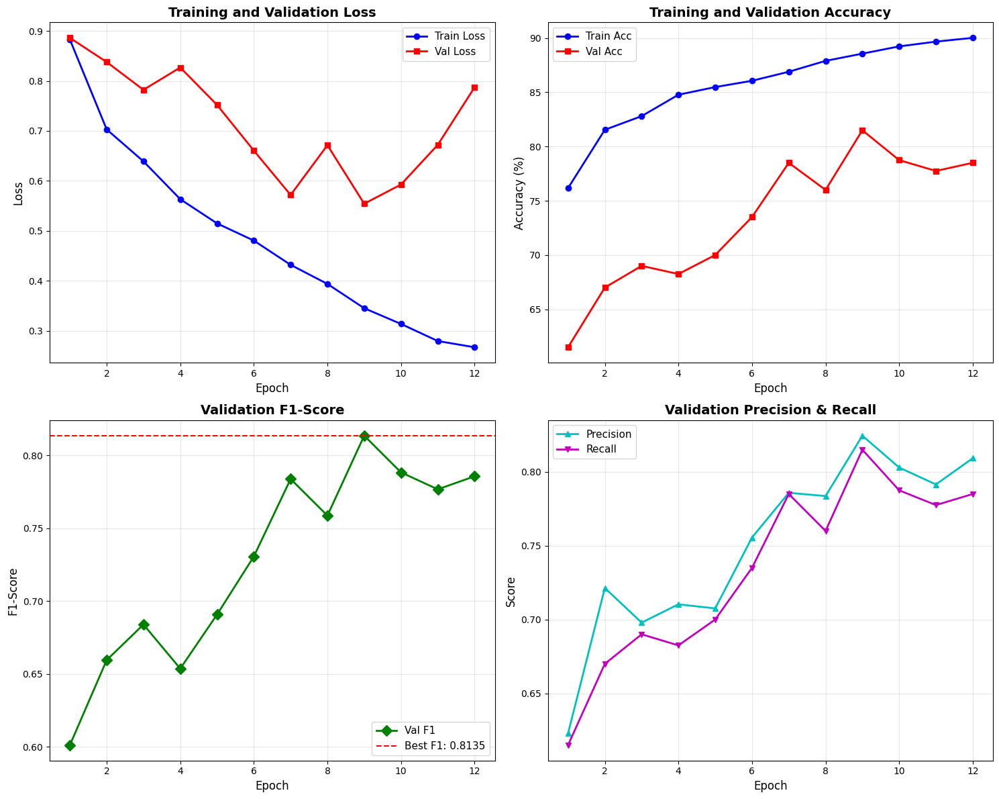

✅ 학습 그래프 저장 완료!


In [8]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix, classification_report
import numpy as np

# ====================================================================
# 1. 학습 그래프
# ====================================================================

fig, axes = plt.subplots(2, 2, figsize=(15, 12))

epochs = range(1, len(history['train_loss']) + 1)

# Loss
axes[0, 0].plot(epochs, history['train_loss'], 'b-o', label='Train Loss', linewidth=2)
axes[0, 0].plot(epochs, history['val_loss'], 'r-s', label='Val Loss', linewidth=2)
axes[0, 0].set_xlabel('Epoch', fontsize=12)
axes[0, 0].set_ylabel('Loss', fontsize=12)
axes[0, 0].set_title('Training and Validation Loss', fontsize=14, fontweight='bold')
axes[0, 0].legend(fontsize=11)
axes[0, 0].grid(True, alpha=0.3)

# Accuracy
axes[0, 1].plot(epochs, history['train_acc'], 'b-o', label='Train Acc', linewidth=2)
axes[0, 1].plot(epochs, history['val_acc'], 'r-s', label='Val Acc', linewidth=2)
axes[0, 1].set_xlabel('Epoch', fontsize=12)
axes[0, 1].set_ylabel('Accuracy (%)', fontsize=12)
axes[0, 1].set_title('Training and Validation Accuracy', fontsize=14, fontweight='bold')
axes[0, 1].legend(fontsize=11)
axes[0, 1].grid(True, alpha=0.3)

# F1-Score
axes[1, 0].plot(epochs, history['val_f1'], 'g-D', label='Val F1', linewidth=2, markersize=8)
axes[1, 0].axhline(y=best_val_f1, color='r', linestyle='--', label=f'Best F1: {best_val_f1:.4f}')
axes[1, 0].set_xlabel('Epoch', fontsize=12)
axes[1, 0].set_ylabel('F1-Score', fontsize=12)
axes[1, 0].set_title('Validation F1-Score', fontsize=14, fontweight='bold')
axes[1, 0].legend(fontsize=11)
axes[1, 0].grid(True, alpha=0.3)

# Precision & Recall
axes[1, 1].plot(epochs, history['val_precision'], 'c-^', label='Precision', linewidth=2)
axes[1, 1].plot(epochs, history['val_recall'], 'm-v', label='Recall', linewidth=2)
axes[1, 1].set_xlabel('Epoch', fontsize=12)
axes[1, 1].set_ylabel('Score', fontsize=12)
axes[1, 1].set_title('Validation Precision & Recall', fontsize=14, fontweight='bold')
axes[1, 1].legend(fontsize=11)
axes[1, 1].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('/content/training_history_5class.png', dpi=150, bbox_inches='tight')
plt.show()

print("✅ 학습 그래프 저장 완료!")

In [9]:
# ====================================================================
# 2. Test 데이터 평가
# ====================================================================

print("="*60)
print("🧪 Test 데이터 평가 중...")
print("="*60)

# Best 모델 로드
model.load_state_dict(torch.load('/content/best_efficientnet_5class.pth'))
model.eval()

all_preds = []
all_labels = []

with torch.no_grad():
    for images, labels in tqdm(test_loader, desc="Testing"):
        images = images.to(device)
        outputs = model(images)
        _, predicted = outputs.max(1)

        all_preds.extend(predicted.cpu().numpy())
        all_labels.extend(labels.numpy())

# 정확도 계산
test_acc = 100. * np.sum(np.array(all_preds) == np.array(all_labels)) / len(all_labels)
test_f1 = f1_score(all_labels, all_preds, average='weighted')
test_precision = precision_score(all_labels, all_preds, average='weighted', zero_division=0)
test_recall = recall_score(all_labels, all_preds, average='weighted', zero_division=0)

print(f"\n🎯 Test 결과:")
print(f"  Accuracy:  {test_acc:.2f}%")
print(f"  F1-Score:  {test_f1:.4f}")
print(f"  Precision: {test_precision:.4f}")
print(f"  Recall:    {test_recall:.4f}")

# Classification Report
print("\n" + "="*60)
print("📋 Classification Report (Test Set):")
print("="*60)
print(classification_report(all_labels, all_preds,
                          target_names=test_dataset.classes,
                          digits=4,
                          zero_division=0))

🧪 Test 데이터 평가 중...


Testing: 100%|██████████| 13/13 [00:00<00:00, 18.51it/s]



🎯 Test 결과:
  Accuracy:  83.46%
  F1-Score:  0.8328
  Precision: 0.8382
  Recall:    0.8346

📋 Classification Report (Test Set):
              precision    recall  f1-score   support

        burn     0.7333    0.8148    0.7719        81
      normal     0.7935    0.9012    0.8439        81
         rot     0.9342    0.8765    0.9045        81
        wilt     0.9048    0.9383    0.9212        81
   yellowing     0.8254    0.6420    0.7222        81

    accuracy                         0.8346       405
   macro avg     0.8382    0.8346    0.8328       405
weighted avg     0.8382    0.8346    0.8328       405



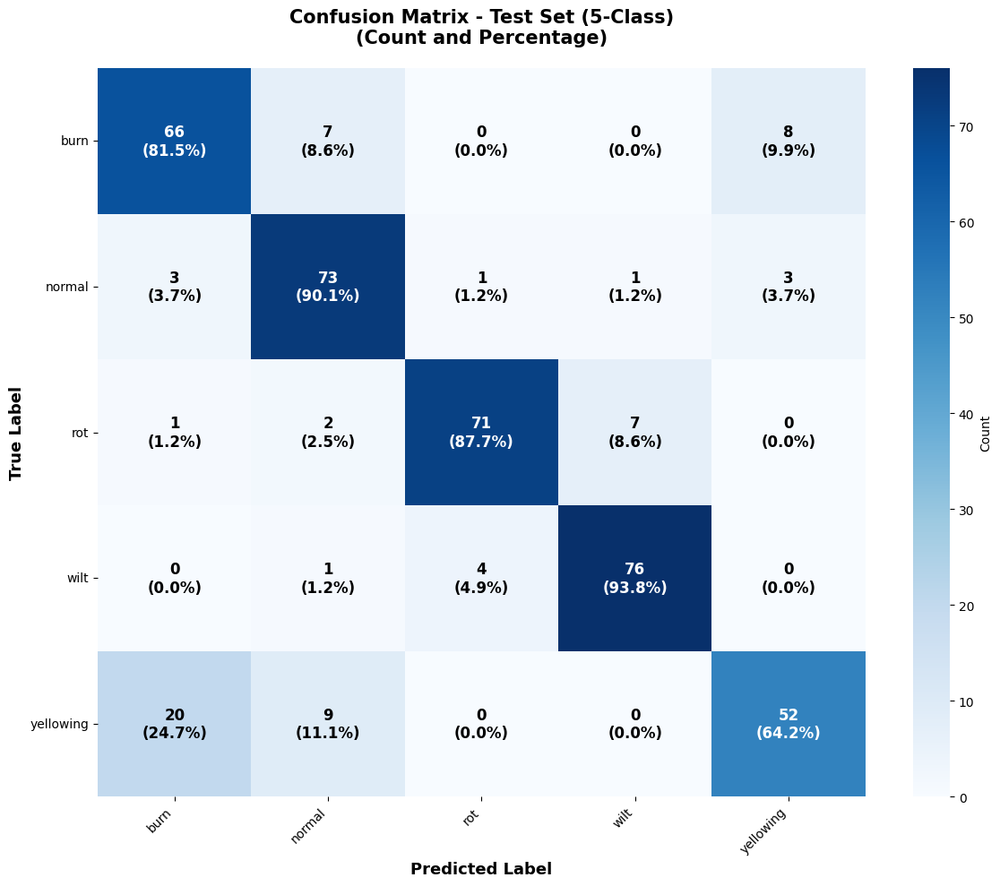

✅ Confusion Matrix 저장 완료!


In [10]:
# ====================================================================
# 3. Confusion Matrix (5x5, 개수 + 비율)
# ====================================================================

# Confusion Matrix 계산
cm = confusion_matrix(all_labels, all_preds)
cm_normalized = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis]

# 시각화
fig, ax = plt.subplots(figsize=(12, 10))

# 히트맵
sns.heatmap(cm, annot=False, fmt='d', cmap='Blues',
            xticklabels=test_dataset.classes,
            yticklabels=test_dataset.classes,
            cbar_kws={'label': 'Count'},
            ax=ax)

# 각 셀에 개수와 비율 추가
for i in range(len(cm)):
    for j in range(len(cm)):
        count = cm[i, j]
        percentage = cm_normalized[i, j] * 100
        text_color = 'white' if cm_normalized[i, j] > 0.5 else 'black'
        ax.text(j + 0.5, i + 0.5, f'{count}\n({percentage:.1f}%)',
                ha='center', va='center',
                color=text_color, fontsize=12, fontweight='bold')

ax.set_xlabel('Predicted Label', fontsize=13, fontweight='bold')
ax.set_ylabel('True Label', fontsize=13, fontweight='bold')
ax.set_title('Confusion Matrix - Test Set (5-Class)\n(Count and Percentage)',
             fontsize=15, fontweight='bold', pad=20)

plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.savefig('/content/confusion_matrix_5class.png', dpi=150, bbox_inches='tight')
plt.show()

print("✅ Confusion Matrix 저장 완료!")

/tmp/ipython-input-1051126644.py:88: UserWarning: Glyph 9989 (\N{WHITE HEAVY CHECK MARK}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipython-input-1051126644.py:88: UserWarning: Glyph 10060 (\N{CROSS MARK}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipython-input-1051126644.py:88: UserWarning: Glyph 50696 (\N{HANGUL SYLLABLE YE}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipython-input-1051126644.py:88: UserWarning: Glyph 52769 (\N{HANGUL SYLLABLE CEUG}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipython-input-1051126644.py:88: UserWarning: Glyph 44208 (\N{HANGUL SYLLABLE GYEOL}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipython-input-1051126644.py:88: UserWarning: Glyph 44284 (\N{HANGUL SYLLABLE GWA}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipython-input-1051126644.py:88: UserWarning: Glyph 49368 (\N{HANGUL SYLLABLE SAEM}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tm

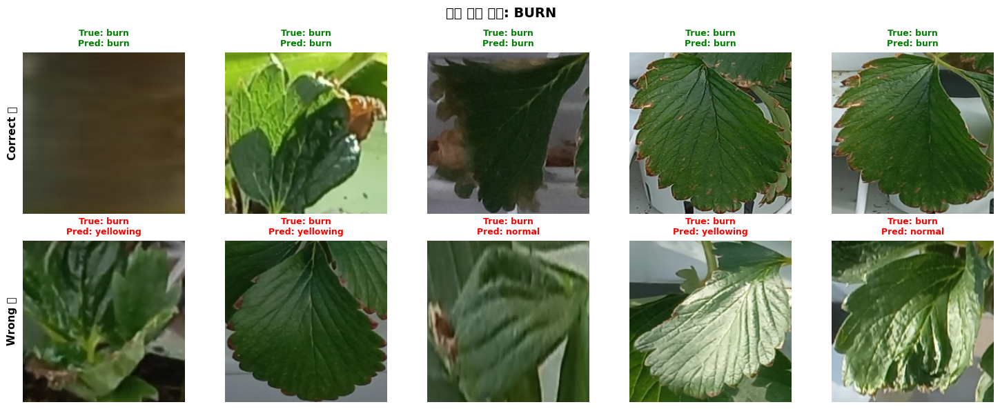

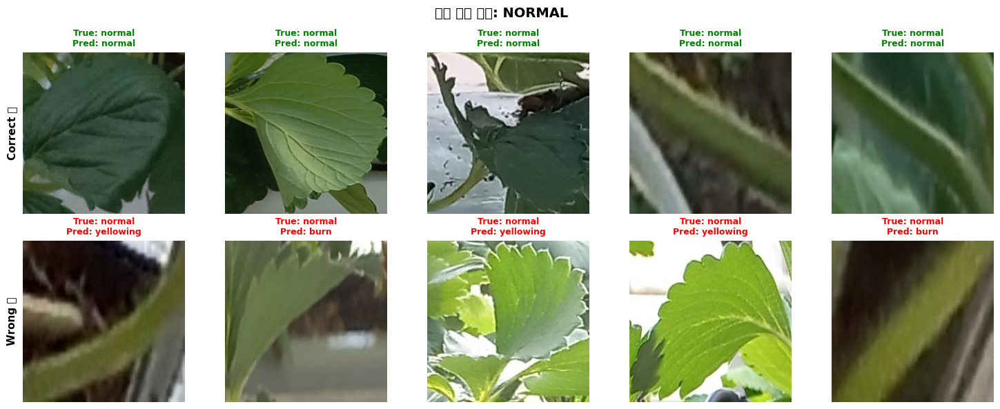

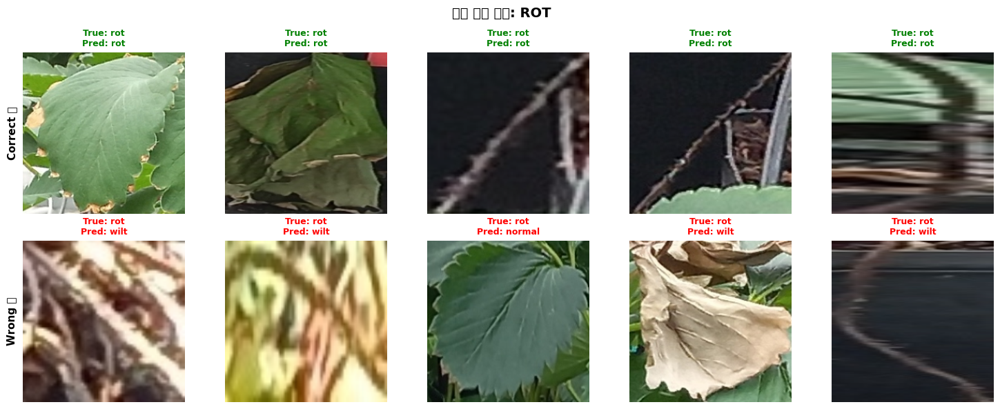

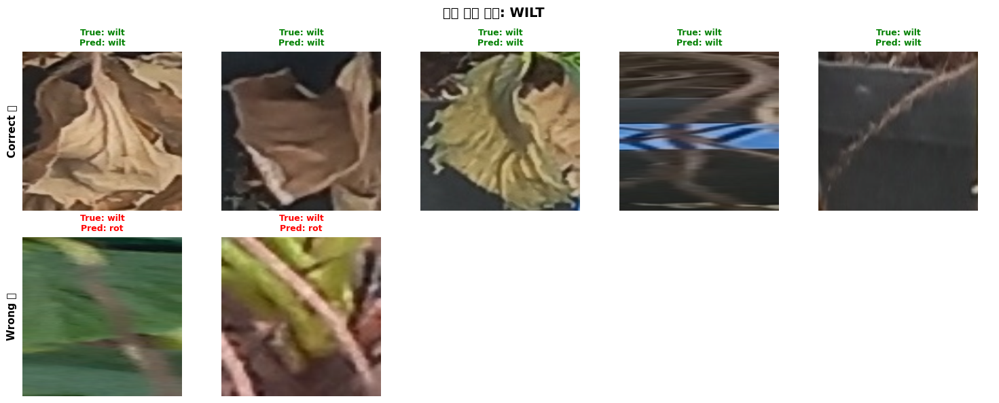

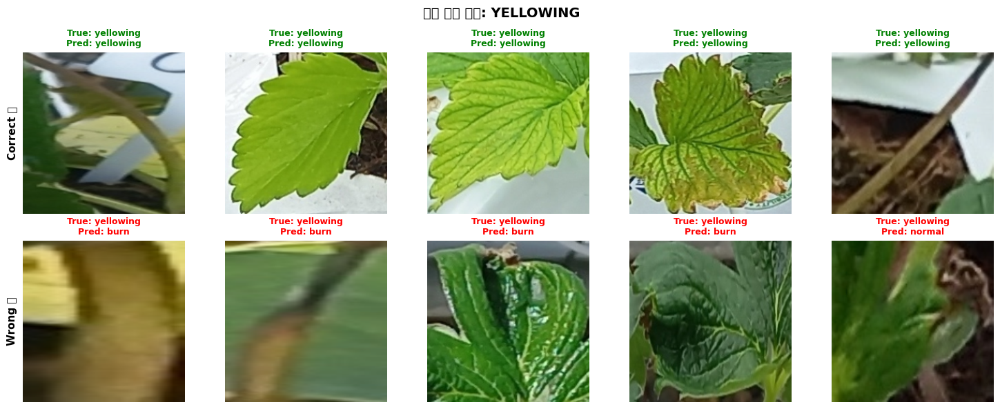

✅ 클래스별 예측 샘플 시각화 저장 완료!


In [ ]:
# ====================================================================
# 4. 클래스별 예측 결과 샘플 시각화 (컴팩트 버전)
# ====================================================================

# 각 클래스별 정답/오답 샘플 수집
correct_samples = {cls: [] for cls in test_dataset.classes}
wrong_samples = {cls: [] for cls in test_dataset.classes}

model.eval()
with torch.no_grad():
    for images, labels in test_loader:
        images_device = images.to(device)
        outputs = model(images_device)
        _, predicted = outputs.max(1)

        for i in range(len(labels)):
            true_label = labels[i].item()
            pred_label = predicted[i].item()
            true_class = test_dataset.classes[true_label]
            pred_class = test_dataset.classes[pred_label]

            sample = {
                'image': images[i],
                'true_label': true_class,
                'pred_label': pred_class
            }

            if true_label == pred_label:
                if len(correct_samples[true_class]) < 5:
                    correct_samples[true_class].append(sample)
            else:
                if len(wrong_samples[true_class]) < 5:
                    wrong_samples[true_class].append(sample)

            if all(len(correct_samples[c]) >= 5 for c in test_dataset.classes) and \
               all(len(wrong_samples[c]) >= 5 for c in test_dataset.classes):
                break

        if all(len(correct_samples[c]) >= 5 for c in test_dataset.classes) and \
           all(len(wrong_samples[c]) >= 5 for c in test_dataset.classes):
            break

# 시각화 - 클래스별로
for cls in test_dataset.classes:
    fig, axes = plt.subplots(2, 5, figsize=(15, 6))

    # 정답 샘플 (첫 번째 행)
    for col_idx in range(5):
        ax = axes[0, col_idx]
        if col_idx < len(correct_samples[cls]):
            sample = correct_samples[cls][col_idx]

            # 이미지 denormalize
            img = sample['image'].permute(1, 2, 0).numpy()
            mean = np.array([0.485, 0.456, 0.406])
            std = np.array([0.229, 0.224, 0.225])
            img = std * img + mean
            img = np.clip(img, 0, 1)

            ax.imshow(img)
            title_text = f"True: {sample['true_label']}\nPred: {sample['pred_label']}"
            ax.set_title(title_text, fontsize=9, fontweight='bold', color='green')
        ax.axis('off')

    # 오답 샘플 (두 번째 행)
    for col_idx in range(5):
        ax = axes[1, col_idx]
        if col_idx < len(wrong_samples[cls]):
            sample = wrong_samples[cls][col_idx]

            # 이미지 denormalize
            img = sample['image'].permute(1, 2, 0).numpy()
            img = std * img + mean
            img = np.clip(img, 0, 1)

            ax.imshow(img)
            title_text = f"True: {sample['true_label']}\nPred: {sample['pred_label']}"
            ax.set_title(title_text, fontsize=9, fontweight='bold', color='red')
        ax.axis('off')

    # 행 제목
    axes[0, 0].text(-0.1, 0.5, 'Correct ✅', transform=axes[0, 0].transAxes,
                    fontsize=11, fontweight='bold', va='center', rotation=90)
    axes[1, 0].text(-0.1, 0.5, 'Wrong ❌', transform=axes[1, 0].transAxes,
                    fontsize=11, fontweight='bold', va='center', rotation=90)

    plt.suptitle(f'예측 결과 샘플: {cls.upper()}', fontsize=14, fontweight='bold')
    plt.tight_layout()
    plt.savefig(f'/content/prediction_samples_{cls}.png', dpi=150, bbox_inches='tight')
    plt.show()

print("✅ 클래스별 예측 샘플 시각화 저장 완료!")